**Week 3 – Shopify Stock Data Understanding, Cleaning & Exploratory Analysis**

Step 1: Import libraries

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Step 2: Upload Shopify stock datase

In [17]:
df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/shopify_stock.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


Step 3: Understand the dataset

In [18]:
df.head()

,date,open,high,low,close,adj_close,volume
0,2015-05-21 00:00:00-04:00,2.800,2.874,2.411,2.568,2.568,123039000
1,2015-05-22 00:00:00-04:00,2.607,3.110,2.600,2.831,2.831,28412000
2,2015-05-26 00:00:00-04:00,2.980,3.034,2.908,2.965,2.965,8202000
3,2015-05-27 00:00:00-04:00,3.067,3.081,2.700,2.750,2.750,7976000
4,2015-05-28 00:00:00-04:00,2.755,2.774,2.648,2.745,2.745,4000000


In [19]:
df.tail()

,date,open,high,low,close,adj_close,volume
2464,2025-03-10 00:00:00-04:00,96.070000,96.186996,91.690002,92.750000,92.750000,16385300
2465,2025-03-11 00:00:00-04:00,92.750000,95.109001,91.150002,92.949997,92.949997,12127100
2466,2025-03-12 00:00:00-04:00,96.669998,99.135002,95.290001,96.529999,96.529999,8531900
2467,2025-03-13 00:00:00-04:00,95.169998,95.529999,89.099998,90.589996,90.589996,11076400
2468,2025-03-14 00:00:00-04:00,94.610001,95.830002,93.059998,94.849998,94.849998,7060700


In [20]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 2469
Number of Columns: 7


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2469 entries, 0 to 2468
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       2469 non-null   object 
 1   open       2469 non-null   float64
 2   high       2469 non-null   float64
 3   low        2469 non-null   float64
 4   close      2469 non-null   float64
 5   adj_close  2469 non-null   float64
 6   volume     2469 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 135.2+ KB


In [22]:
df.describe()

,open,high,low,close,adj_close,volume
count,2469.000000,2469.000000,2469.000000,2469.000000,2469.000000,2.469000e+03
mean,48.464345,49.505495,47.347795,48.456613,48.456613,1.657049e+07
std,43.633916,44.470235,42.642546,43.573362,43.573362,1.436909e+07
min,1.939000,1.985000,1.848000,1.933000,1.933000,1.039000e+06
25%,10.479000,10.635000,10.275000,10.450000,10.450000,8.098000e+06
50%,35.640999,36.879002,34.655998,35.874001,35.874001,1.275860e+07
75%,76.080002,77.169998,74.589996,75.800003,75.800003,2.060200e+07
max,171.800003,176.291794,168.509506,169.059998,169.059998,2.089590e+08


Step 4: Standardize column names

In [23]:
df.columns = df.columns.str.strip().str.lower()

print(df.columns.tolist())

['date', 'open', 'high', 'low', 'close', 'adj_close', 'volume']


Step 5: Convert date into datetime format

In [24]:
df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce',
    utc=True
)

print(df['date'].dtype)

df[['date']].head()

datetime64[ns, UTC]


,date
0,2015-05-21 04:00:00+00:00
1,2015-05-22 04:00:00+00:00
2,2015-05-26 04:00:00+00:00
3,2015-05-27 04:00:00+00:00
4,2015-05-28 04:00:00+00:00


Step 6: Convert numerical columns

In [25]:
numeric_columns = [
    'open',
    'high',
    'low',
    'close',
    'adj_close',
    'volume'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2469 entries, 0 to 2468
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype              
---  ------     --------------  -----              
 0   date       2469 non-null   datetime64[ns, UTC]
 1   open       2469 non-null   float64            
 2   high       2469 non-null   float64            
 3   low        2469 non-null   float64            
 4   close      2469 non-null   float64            
 5   adj_close  2469 non-null   float64            
 6   volume     2469 non-null   int64              
dtypes: datetime64[ns, UTC](1), float64(5), int64(1)
memory usage: 135.2 KB


Step 7: Handle missing values

In [26]:
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
date         0
open         0
high         0
low          0
close        0
adj_close    0
volume       0
dtype: int64


In [27]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage)

date         0.0
open         0.0
high         0.0
low          0.0
close        0.0
adj_close    0.0
volume       0.0
dtype: float64


In [28]:
df = df.dropna(subset=['date'])

In [29]:
df = df.dropna(subset=numeric_columns)

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
date         0
open         0
high         0
low          0
close        0
adj_close    0
volume       0
dtype: int64


Step 8: Check duplicate records

In [30]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [31]:
print("Duplicate dates:", df['date'].duplicated().sum())

Duplicate dates: 0


Step 9: Sort data and set date as index

In [32]:
df = df.sort_values('date')

df = df.set_index('date')

display(df.head())

,open,high,low,close,adj_close,volume
date,,,,,,
2015-05-21 04:00:00+00:00,2.800,2.874,2.411,2.568,2.568,123039000
2015-05-22 04:00:00+00:00,2.607,3.110,2.600,2.831,2.831,28412000
2015-05-26 04:00:00+00:00,2.980,3.034,2.908,2.965,2.965,8202000
2015-05-27 04:00:00+00:00,3.067,3.081,2.700,2.750,2.750,7976000
2015-05-28 04:00:00+00:00,2.755,2.774,2.648,2.745,2.745,4000000


In [33]:
print(df.index)

DatetimeIndex(['2015-05-21 04:00:00+00:00', '2015-05-22 04:00:00+00:00',
               '2015-05-26 04:00:00+00:00', '2015-05-27 04:00:00+00:00',
               '2015-05-28 04:00:00+00:00', '2015-05-29 04:00:00+00:00',
               '2015-06-01 04:00:00+00:00', '2015-06-02 04:00:00+00:00',
               '2015-06-03 04:00:00+00:00', '2015-06-04 04:00:00+00:00',
               ...
               '2025-03-03 05:00:00+00:00', '2025-03-04 05:00:00+00:00',
               '2025-03-05 05:00:00+00:00', '2025-03-06 05:00:00+00:00',
               '2025-03-07 05:00:00+00:00', '2025-03-10 04:00:00+00:00',
               '2025-03-11 04:00:00+00:00', '2025-03-12 04:00:00+00:00',
               '2025-03-13 04:00:00+00:00', '2025-03-14 04:00:00+00:00'],
              dtype='datetime64[ns, UTC]', name='date', length=2469, freq=None)


Step 10: Validate stock price attributes

In [34]:
invalid_records = df[
    (df[['open', 'high', 'low', 'close', 'adj_close']] <= 0).any(axis=1)
    | (df['volume'] < 0)
]

print("Number of invalid records:", len(invalid_records))

display(invalid_records.head())

Number of invalid records: 0


,open,high,low,close,adj_close,volume
date,,,,,,


In [35]:
invalid_ohlc = df[
    (df['high'] < df[['open', 'close', 'low']].max(axis=1))
    | (df['low'] > df[['open', 'close', 'high']].min(axis=1))
]

print("Invalid OHLC records:", len(invalid_ohlc))

display(invalid_ohlc.head())

Invalid OHLC records: 0


,open,high,low,close,adj_close,volume
date,,,,,,


Step 11: Calculate daily price change

In [36]:
df['daily_price_change'] = df['close'] - df['open']

display(
    df[['open', 'close', 'daily_price_change']].head(10)
)

,open,close,daily_price_change
date,,,
2015-05-21 04:00:00+00:00,2.800,2.568,-0.232
2015-05-22 04:00:00+00:00,2.607,2.831,0.224
2015-05-26 04:00:00+00:00,2.980,2.965,-0.015
2015-05-27 04:00:00+00:00,3.067,2.750,-0.317
2015-05-28 04:00:00+00:00,2.755,2.745,-0.010
2015-05-29 04:00:00+00:00,2.725,2.720,-0.005
2015-06-01 04:00:00+00:00,2.720,2.733,0.013
2015-06-02 04:00:00+00:00,2.747,2.695,-0.052
2015-06-03 04:00:00+00:00,2.676,2.744,0.068


Step 12: Calculate daily return percentage

In [37]:
df['daily_return_percentage'] = (
    df['adj_close'].pct_change() * 100
)

display(
    df[['adj_close', 'daily_return_percentage']].head(10)
)

,adj_close,daily_return_percentage
date,,
2015-05-21 04:00:00+00:00,2.568,NaN
2015-05-22 04:00:00+00:00,2.831,10.241433
2015-05-26 04:00:00+00:00,2.965,4.733303
2015-05-27 04:00:00+00:00,2.750,-7.251262
2015-05-28 04:00:00+00:00,2.745,-0.181822
2015-05-29 04:00:00+00:00,2.720,-0.910742
2015-06-01 04:00:00+00:00,2.733,0.477942
2015-06-02 04:00:00+00:00,2.695,-1.390417
2015-06-03 04:00:00+00:00,2.744,1.818183


Step 13: Calculate daily trading range

In [38]:
df['daily_range'] = df['high'] - df['low']

display(
    df[['high', 'low', 'daily_range']].head()
)

,high,low,daily_range
date,,,
2015-05-21 04:00:00+00:00,2.874,2.411,0.463
2015-05-22 04:00:00+00:00,3.110,2.600,0.510
2015-05-26 04:00:00+00:00,3.034,2.908,0.126
2015-05-27 04:00:00+00:00,3.081,2.700,0.381
2015-05-28 04:00:00+00:00,2.774,2.648,0.126


Step 14: Calculate range percentage

In [39]:
df['range_percentage'] = (
    (df['high'] - df['low']) / df['open']
) * 100

display(
    df[['open', 'high', 'low', 'range_percentage']].head()
)

,open,high,low,range_percentage
date,,,,
2015-05-21 04:00:00+00:00,2.800,2.874,2.411,16.535717
2015-05-22 04:00:00+00:00,2.607,3.110,2.600,19.562715
2015-05-26 04:00:00+00:00,2.980,3.034,2.908,4.228185
2015-05-27 04:00:00+00:00,3.067,3.081,2.700,12.422564
2015-05-28 04:00:00+00:00,2.755,2.774,2.648,4.573500


Step 15: Analyze stock price attributes

In [40]:
price_summary = df[
    ['open', 'high', 'low', 'close', 'adj_close']
].describe()

display(price_summary)

,open,high,low,close,adj_close
count,2469.000000,2469.000000,2469.000000,2469.000000,2469.000000
mean,48.464345,49.505495,47.347795,48.456613,48.456613
std,43.633916,44.470235,42.642546,43.573362,43.573362
min,1.939000,1.985000,1.848000,1.933000,1.933000
25%,10.479000,10.635000,10.275000,10.450000,10.450000
50%,35.640999,36.879002,34.655998,35.874001,35.874001
75%,76.080002,77.169998,74.589996,75.800003,75.800003
max,171.800003,176.291794,168.509506,169.059998,169.059998


Step 16: Analyze trading volume

In [41]:
print("Trading Volume Statistics")

print("Average Volume:", df['volume'].mean())
print("Maximum Volume:", df['volume'].max())
print("Minimum Volume:", df['volume'].min())
print("Total Volume:", df['volume'].sum())

Trading Volume Statistics
Average Volume: 16570491.778047793
Maximum Volume: 208959000
Minimum Volume: 1039000
Total Volume: 40912544200


In [42]:
df['volume'].describe()

,volume
count,2.469000e+03
mean,1.657049e+07
std,1.436909e+07
min,1.039000e+06
25%,8.098000e+06
50%,1.275860e+07
75%,2.060200e+07
max,2.089590e+08


Step 17: Visualize trading volume distribution

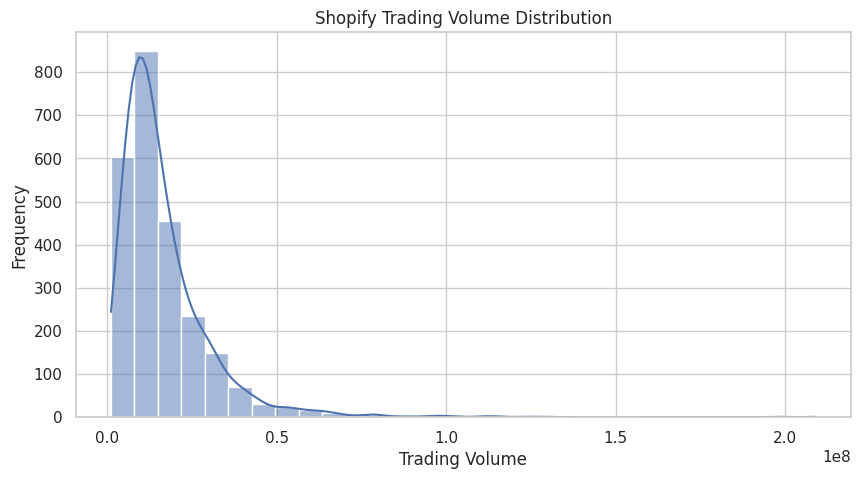

In [43]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['volume'],
    bins=30,
    kde=True
)

plt.title("Shopify Trading Volume Distribution")
plt.xlabel("Trading Volume")
plt.ylabel("Frequency")

plt.show()

Step 18: Detect anomalous trading days using IQR

In [44]:
Q1 = df['volume'].quantile(0.25)
Q3 = df['volume'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -10658000.0
Upper Bound: 39358000.0


In [45]:
anomalous_days = df[
    (df['volume'] < lower_bound) |
    (df['volume'] > upper_bound)
]

print("Number of anomalous trading days:", len(anomalous_days))

display(anomalous_days)

Number of anomalous trading days: 136


,open,high,low,close,adj_close,volume,daily_price_change,daily_return_percentage,daily_range,range_percentage
date,,,,,,,,,,
2015-05-21 04:00:00+00:00,2.800000,2.874000,2.411000,2.568000,2.568000,123039000,-0.232000,NaN,0.463000,16.535717
2016-08-17 04:00:00+00:00,3.890000,3.957000,3.860000,3.874000,3.874000,58113000,-0.016000,0.964300,0.097000,2.493576
2017-01-05 05:00:00+00:00,4.447000,4.794000,4.425000,4.768000,4.768000,50702000,0.321000,8.019939,0.369000,8.297728
2017-02-15 05:00:00+00:00,5.487000,6.149000,5.430000,6.061000,6.061000,56969000,0.574000,8.135591,0.719000,13.103706
2017-05-02 04:00:00+00:00,8.041000,8.458000,7.757100,8.298000,8.298000,61484000,0.257000,7.403579,0.700900,8.716578
...,...,...,...,...,...,...,...,...,...,...
2023-11-02 04:00:00+00:00,57.639999,60.150002,55.507000,59.700001,59.700001,43602900,2.060001,22.361139,4.643002,8.055173
2024-02-13 05:00:00+00:00,77.800003,83.489998,77.010002,77.180000,77.180000,40164900,-0.620003,-13.397668,6.479996,8.329043
2024-05-08 04:00:00+00:00,63.669998,64.199997,60.639999,62.730000,62.730000,58311600,-0.939999,-18.585338,3.559998,5.591327


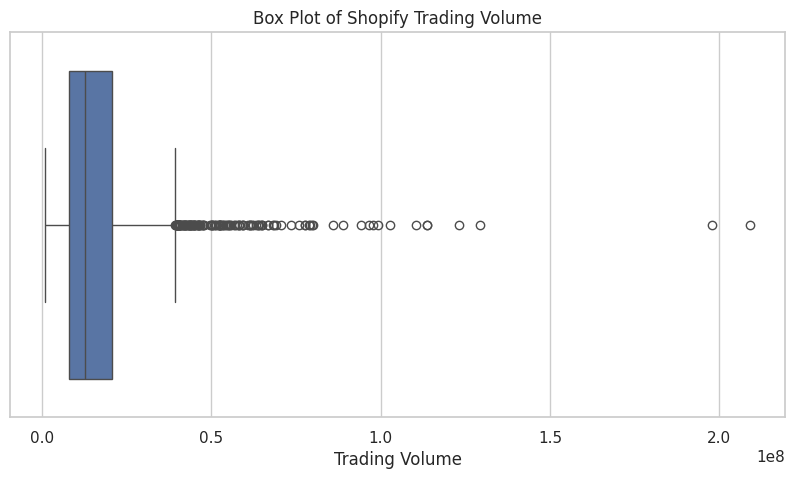

In [46]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['volume'])

plt.title("Box Plot of Shopify Trading Volume")
plt.xlabel("Trading Volume")

plt.show()

Step 19: Calculate mean daily return

In [47]:
returns = df['daily_return_percentage'].dropna()

mean_return = returns.mean()

print("Mean Daily Return:", mean_return)

Mean Daily Return: 0.2148062655694457


Step 20: Calculate variance of daily returns

In [48]:
variance_return = returns.var()

print("Variance of Daily Returns:", variance_return)

Variance of Daily Returns: 13.78075206243252


Step 21: Calculate standard deviation

In [49]:
std_return = returns.std()

print("Standard Deviation:", std_return)

Standard Deviation: 3.712243534903458


Step 22: Generate return statistics summary

In [50]:
return_statistics = pd.DataFrame({
    'Metric': [
        'Mean',
        'Variance',
        'Standard Deviation',
        'Minimum Return',
        'Maximum Return',
        'Median Return'
    ],

    'Value': [
        returns.mean(),
        returns.var(),
        returns.std(),
        returns.min(),
        returns.max(),
        returns.median()
    ]
})

display(return_statistics)

,Metric,Value
0,Mean,0.214806
1,Variance,13.780752
2,Standard Deviation,3.712244
3,Minimum Return,-18.585338
4,Maximum Return,23.838337
5,Median Return,0.203627


Step 24: Analyze monthly trading volume

In [51]:
monthly_volume = df['volume'].resample('ME').sum()

display(monthly_volume)

,volume
date,
2015-05-31 00:00:00+00:00,174183000
2015-06-30 00:00:00+00:00,131118000
2015-07-31 00:00:00+00:00,89926000
2015-08-31 00:00:00+00:00,65836000
2015-09-30 00:00:00+00:00,72092000
...,...
2024-11-30 00:00:00+00:00,232230900
2024-12-31 00:00:00+00:00,129205100
2025-01-31 00:00:00+00:00,125289300


Step 25: Visualize daily price change

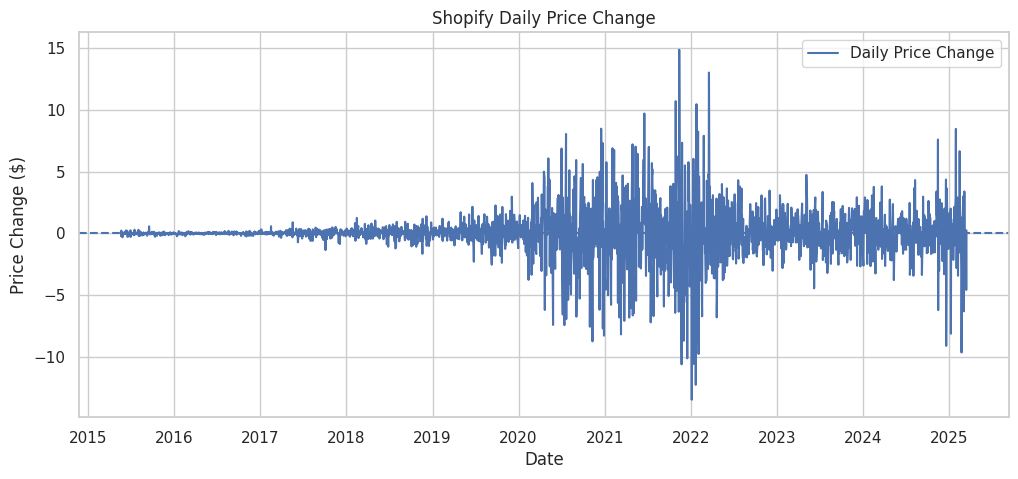

In [52]:
plt.figure(figsize=(12, 5))

plt.plot(
    df.index,
    df['daily_price_change'],
    label='Daily Price Change'
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.title("Shopify Daily Price Change")
plt.xlabel("Date")
plt.ylabel("Price Change ($)")

plt.legend()
plt.show()

Step 26: Visualize daily return percentage

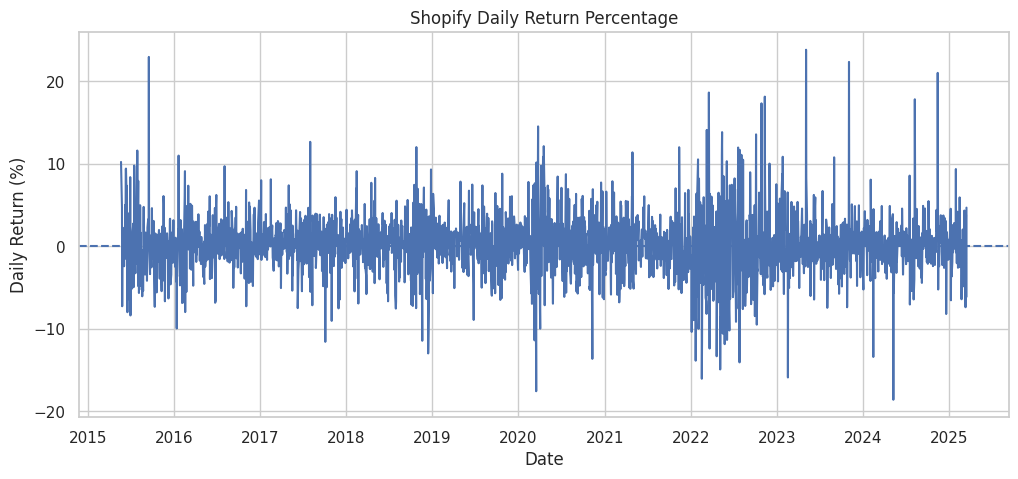

In [53]:
plt.figure(figsize=(12, 5))

plt.plot(
    df.index,
    df['daily_return_percentage']
)

plt.axhline(y=0, linestyle='--')

plt.title("Shopify Daily Return Percentage")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

plt.show()

Step 27: Generate final stock summary

In [54]:
stock_summary = pd.DataFrame({
    'Metric': [
        'First Trading Date',
        'Last Trading Date',
        'Number of Trading Days',
        'Average Opening Price',
        'Average Closing Price',
        'Highest Closing Price',
        'Lowest Closing Price',
        'Average Daily Price Change',
        'Average Daily Return (%)',
        'Daily Return Variance',
        'Daily Return Standard Deviation',
        'Average Trading Volume',
        'Maximum Trading Volume'
    ],

    'Value': [
        df.index.min(),
        df.index.max(),
        len(df),
        df['open'].mean(),
        df['close'].mean(),
        df['close'].max(),
        df['close'].min(),
        df['daily_price_change'].mean(),
        returns.mean(),
        returns.var(),
        returns.std(),
        df['volume'].mean(),
        df['volume'].max()
    ]
})

display(stock_summary)

,Metric,Value
0,First Trading Date,2015-05-21 04:00:00+00:00
1,Last Trading Date,2025-03-14 04:00:00+00:00
2,Number of Trading Days,2469
3,Average Opening Price,48.464345
4,Average Closing Price,48.456613
5,Highest Closing Price,169.059998
6,Lowest Closing Price,1.933
7,Average Daily Price Change,-0.007732
8,Average Daily Return (%),0.214806
9,Daily Return Variance,13.780752


Step 28: Export cleaned dataset and reports

In [55]:
os.makedirs("reports", exist_ok=True)

df.to_csv("Shopify_Stock_Cleaned.csv")

stock_summary.to_csv(
    "reports/stock_summary.csv",
    index=False
)

return_statistics.to_csv(
    "reports/return_statistics.csv",
    index=False
)

monthly_volume.to_csv(
    "reports/monthly_volume_summary.csv"
)

anomalous_days.to_csv(
    "reports/anomalous_trading_days.csv"
)

print("All files exported successfully!")

All files exported successfully!


Step 29: Final validation

In [56]:
print("FINAL DATASET SUMMARY")

print("Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst Five Records:")
display(df.head())

print("\nLast Five Records:")
display(df.tail())

FINAL DATASET SUMMARY
Shape: (2469, 10)

Data Types:
open                       float64
high                       float64
low                        float64
close                      float64
adj_close                  float64
volume                       int64
daily_price_change         float64
daily_return_percentage    float64
daily_range                float64
range_percentage           float64
dtype: object

Missing Values:
open                       0
high                       0
low                        0
close                      0
adj_close                  0
volume                     0
daily_price_change         0
daily_return_percentage    1
daily_range                0
range_percentage           0
dtype: int64

First Five Records:


,open,high,low,close,adj_close,volume,daily_price_change,daily_return_percentage,daily_range,range_percentage
date,,,,,,,,,,
2015-05-21 04:00:00+00:00,2.800,2.874,2.411,2.568,2.568,123039000,-0.232,NaN,0.463,16.535717
2015-05-22 04:00:00+00:00,2.607,3.110,2.600,2.831,2.831,28412000,0.224,10.241433,0.510,19.562715
2015-05-26 04:00:00+00:00,2.980,3.034,2.908,2.965,2.965,8202000,-0.015,4.733303,0.126,4.228185
2015-05-27 04:00:00+00:00,3.067,3.081,2.700,2.750,2.750,7976000,-0.317,-7.251262,0.381,12.422564
2015-05-28 04:00:00+00:00,2.755,2.774,2.648,2.745,2.745,4000000,-0.010,-0.181822,0.126,4.573500



Last Five Records:


,open,high,low,close,adj_close,volume,daily_price_change,daily_return_percentage,daily_range,range_percentage
date,,,,,,,,,,
2025-03-10 04:00:00+00:00,96.070000,96.186996,91.690002,92.750000,92.750000,16385300,-3.320000,-7.370416,4.496994,4.680956
2025-03-11 04:00:00+00:00,92.750000,95.109001,91.150002,92.949997,92.949997,12127100,0.199997,0.215630,3.959000,4.268463
2025-03-12 04:00:00+00:00,96.669998,99.135002,95.290001,96.529999,96.529999,8531900,-0.139999,3.851535,3.845001,3.977450
2025-03-13 04:00:00+00:00,95.169998,95.529999,89.099998,90.589996,90.589996,11076400,-4.580002,-6.153530,6.430000,6.756331
2025-03-14 04:00:00+00:00,94.610001,95.830002,93.059998,94.849998,94.849998,7060700,0.239998,4.702508,2.770004,2.927813
